# Dar_050 - Polar thermal: native mesh, weighting, extremes and resource-model support

## Questions
- Do native facet sizes and triangle versus area weighting change regional thermal distributions?
- What supported spatial upper tails exist, and how many centre-selected triangles cross regional bounds?
- What does model ice-stability depth mean, including excluded values?
- Are old Dar_044 regional summaries preserved, and what cannot be inferred for Stage 4?

All selected south PRP facets are read in bounded chunks. Areas are native 3-D triangular-facet areas, not geodesic, clipped ROI or buildable areas. Histogram quantiles are intervals, not exact quantiles. Annual surface maximum and annual mean at 2 cm are **different statistics/depths**, not a thermal-cycle amplitude. The provider marks start/stop times inapplicable: this static model cannot acquire artificial month/season/year histories.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'env_algo_task/EDA').is_dir())
sys.path.insert(0,str(root/'env_algo_task/EDA/Moon/Stage3_Requirements'))
from stage3_polar_thermal_eda import execute

## Execute full native-mesh study
The complete model follows a separate bounded sample validation. Science/label receipts, source fields, output hashes and provenance are retained.

In [2]:
folder,findings=execute(sample=False)
display(findings)

PRP triangles read: 40000


PRP triangles read: 840000


PRP triangles read: 1640000


PRP triangles read: 2440000


{
  "subject": "polar_thermal",
  "sample": false,
  "native_triangles": 2880000,
  "tables": {
    "native_model_statistics": 32,
    "native_model_histograms": 9248,
    "regional_support": 8,
    "resource_depth_classes": 24,
    "regional_triangle_values": 25058,
    "field_time_applicability": 15,
    "crosscheck_Dar044": 8,
    "stage4_polar_thermal_proposals": 5
  },
  "time_applicability": "provider start/stop explicitly inapplicable; annual model statistics cannot supply calendar histories",
  "base_conclusion": "Spatial/model thermal tails, mesh support and ice-stability context are available. Unlike depth/statistics, unvalidated footprints and absent chronological response prevent component thermal or resource-operability conclusions.",
  "full_source_scope": "all selected native south PRP facets",
  "pipeline_changed": false,
  "adopted_limits": false,
  "operational_status": "Unknown",
  "remaining": [
    "Mission-local chronological thermal forcing and component response

{'subject': 'polar_thermal',
 'sample': False,
 'native_triangles': 2880000,
 'tables': {'native_model_statistics': 32,
  'native_model_histograms': 9248,
  'regional_support': 8,
  'resource_depth_classes': 24,
  'regional_triangle_values': 25058,
  'field_time_applicability': 15,
  'crosscheck_Dar044': 8,
  'stage4_polar_thermal_proposals': 5},
 'time_applicability': 'provider start/stop explicitly inapplicable; annual model statistics cannot supply calendar histories',
 'base_conclusion': 'Spatial/model thermal tails, mesh support and ice-stability context are available. Unlike depth/statistics, unvalidated footprints and absent chronological response prevent component thermal or resource-operability conclusions.',
 'full_source_scope': 'all selected native south PRP facets',
 'pipeline_changed': False,
 'adopted_limits': False,
 'operational_status': 'Unknown',
 'remaining': ['Mission-local chronological thermal forcing and component response',
  'Validated actual candidate footpri

## Native support and weighting
Region boxes are context, not actual validated mission footprints. Centre inclusion can select boundary-crossing triangles; full facet areas are not clipped to the box.

,region,triangles,positive_area_triangles,native_facet_area_m2,not_wholly_inside_ROI,area_scope
0,whole_south_product,2880000,2880000,3.710274e+11,0,"3-D native facet area, selected by triangle ce..."
1,A3CLR22_10_Leibnitz_Beta_Plateau,2048,2048,2.714256e+08,248,"3-D native facet area, selected by triangle ce..."
2,A3CLR22_11_Malapert_Massif,3486,3486,4.721324e+08,286,"3-D native facet area, selected by triangle ce..."
3,A3CLR22_12_deGerlache_Kocher_Massif,3121,3121,4.139168e+08,157,"3-D native facet area, selected by triangle ce..."
4,A3CLR22_2_Haworth,6962,6962,9.097675e+08,234,"3-D native facet area, selected by triangle ce..."
5,A3CLR22_3_Faustini_Rim_A,3160,3160,4.125828e+08,196,"3-D native facet area, selected by triangle ce..."
6,A3CLR22_4_deGerlache_Rim_2,3121,3121,4.110140e+08,79,"3-D native facet area, selected by triangle ce..."
7,A3CLR22_5_Connecting_Ridge_Extension,3160,3160,4.198621e+08,196,"3-D native facet area, selected by triangle ce..."


,region,field,supported_triangles,native_facet_area_m2,triangle_weighted_mean,facet_area_weighted_mean,minimum,maximum,underflow_triangles,overflow_triangles,...,facet_area_p50_upper,triangle_p95_lower,triangle_p95_upper,facet_area_p95_lower,facet_area_p95_upper,triangle_p99_lower,triangle_p99_upper,facet_area_p99_lower,facet_area_p99_upper,summary_scope
0,whole_south_product,temp_avg,2880000,3.710274e+11,124.094148,124.008045,25.115000,212.819000,0,0,...,132.000000,169.000000,170.000000,169.000000,170.000000,183.000000,184.000000,184.000000,185.000000,native facets selected by centre; area not cli...
1,whole_south_product,temp_max,2880000,3.710274e+11,241.548511,241.678849,26.770000,350.772000,0,0,...,250.000000,299.000000,300.000000,300.000000,301.000000,318.000000,319.000000,318.000000,319.000000,native facets selected by centre; area not cli...
2,whole_south_product,ice_depth,932242,1.207517e+11,0.171491,0.170822,0.000000,1.773810,0,0,...,0.100000,0.675000,0.700000,0.675000,0.700000,0.925000,0.950000,0.925000,0.950000,native facets selected by centre; area not cli...
3,whole_south_product,facet_area,2880000,3.710274e+11,128828.962859,128913.525372,123096.117337,187282.879623,0,0,...,138949.549437,121818.791201,138949.549437,121818.791201,138949.549437,138949.549437,158489.319246,138949.549437,158489.319246,native facets selected by centre; area not cli...
4,A3CLR22_10_Leibnitz_Beta_Plateau,temp_avg,2048,2.714256e+08,117.335227,117.304287,40.873000,173.545000,0,0,...,119.000000,155.000000,156.000000,154.000000,155.000000,164.000000,165.000000,164.000000,165.000000,native facets selected by centre; area not cli...
5,A3CLR22_10_Leibnitz_Beta_Plateau,temp_max,2048,2.714256e+08,249.041230,249.737134,60.950000,314.910000,0,0,...,256.000000,291.000000,292.000000,291.000000,292.000000,300.000000,301.000000,301.000000,302.000000,native facets selected by centre; area not cli...
6,A3CLR22_10_Leibnitz_Beta_Plateau,ice_depth,963,1.280945e+08,0.314313,0.318765,0.000000,1.542740,0,0,...,0.275000,0.875000,0.900000,0.875000,0.900000,1.150000,1.175000,1.150000,1.175000,native facets selected by centre; area not cli...
7,A3CLR22_10_Leibnitz_Beta_Plateau,facet_area,2048,2.714256e+08,132532.047343,132658.571126,128732.174976,152820.621190,0,0,...,138949.549437,138949.549437,158489.319246,138949.549437,158489.319246,138949.549437,158489.319246,138949.549437,158489.319246,native facets selected by centre; area not cli...
8,A3CLR22_11_Malapert_Massif,temp_avg,3486,4.721324e+08,143.476289,144.314585,53.642000,201.382000,0,0,...,144.000000,188.000000,189.000000,188.000000,189.000000,193.000000,194.000000,193.000000,194.000000,native facets selected by centre; area not cli...
9,A3CLR22_11_Malapert_Massif,temp_max,3486,4.721324e+08,274.035468,275.149430,131.754000,342.081000,0,0,...,279.000000,322.000000,323.000000,322.000000,323.000000,328.000000,329.000000,330.000000,331.000000,native facets selected by centre; area not cli...


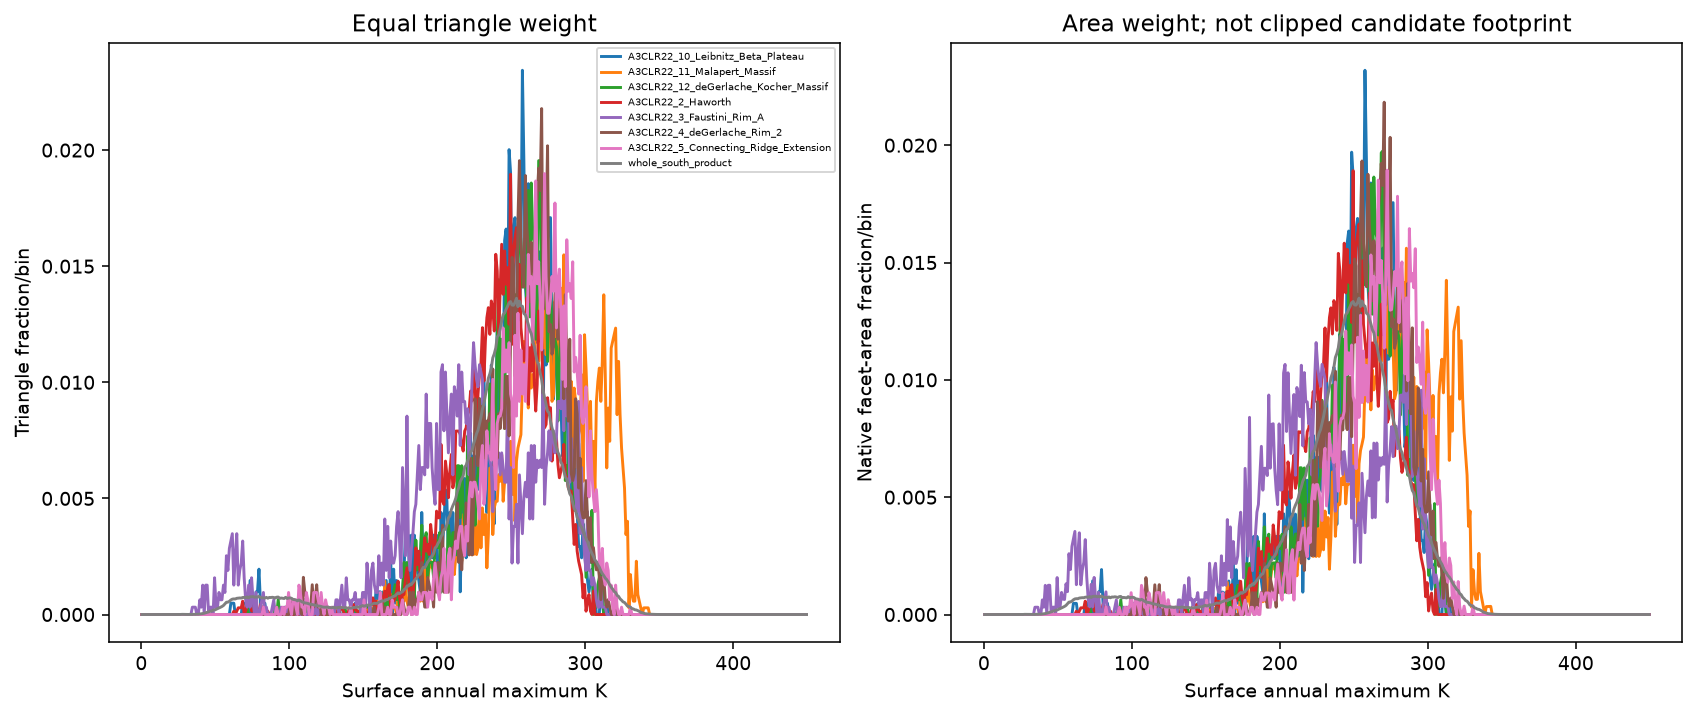

In [3]:
display(pd.read_csv(folder/'regional_support.csv'))
display(pd.read_csv(folder/'native_model_statistics.csv'))
display(Image(filename=str(folder/'surface_max_weighting_comparison.png')))

## Thermal/resource interpretation
Hotter annual model maxima are spatial context, not component temperatures or dated events. Model stability is not detected ice, abundance or extraction feasibility; excluded depth is not proof of absence.

,region,depth_class,triangles,native_facet_area_m2,meaning
0,whole_south_product,model_surface_stable,18375,2.435205e+09,"model sublimation-stability depth, not detecti..."
1,whole_south_product,model_positive_depth,913867,1.183165e+11,"model sublimation-stability depth, not detecti..."
2,whole_south_product,excluded_or_unknown_depth,1947758,2.502757e+11,"model sublimation-stability depth, not detecti..."
3,A3CLR22_10_Leibnitz_Beta_Plateau,model_surface_stable,3,3.911420e+05,"model sublimation-stability depth, not detecti..."
4,A3CLR22_10_Leibnitz_Beta_Plateau,model_positive_depth,960,1.277034e+08,"model sublimation-stability depth, not detecti..."
5,A3CLR22_10_Leibnitz_Beta_Plateau,excluded_or_unknown_depth,1085,1.433311e+08,"model sublimation-stability depth, not detecti..."
6,A3CLR22_11_Malapert_Massif,model_surface_stable,0,0.000000e+00,"model sublimation-stability depth, not detecti..."
7,A3CLR22_11_Malapert_Massif,model_positive_depth,791,1.036169e+08,"model sublimation-stability depth, not detecti..."
8,A3CLR22_11_Malapert_Massif,excluded_or_unknown_depth,2695,3.685155e+08,"model sublimation-stability depth, not detecti..."
9,A3CLR22_12_deGerlache_Kocher_Massif,model_surface_stable,8,1.043367e+06,"model sublimation-stability depth, not detecti..."


,field,unit,time_nil_reason,dated_time_series
0,tri1_x,km,inapplicable,False
1,tri1_y,km,inapplicable,False
2,tri1_z,km,inapplicable,False
3,tri2_x,km,inapplicable,False
4,tri2_y,km,inapplicable,False
5,tri2_z,km,inapplicable,False
6,tri3_x,km,inapplicable,False
7,tri3_y,km,inapplicable,False
8,tri3_z,km,inapplicable,False
9,tri_clon,degree,inapplicable,False


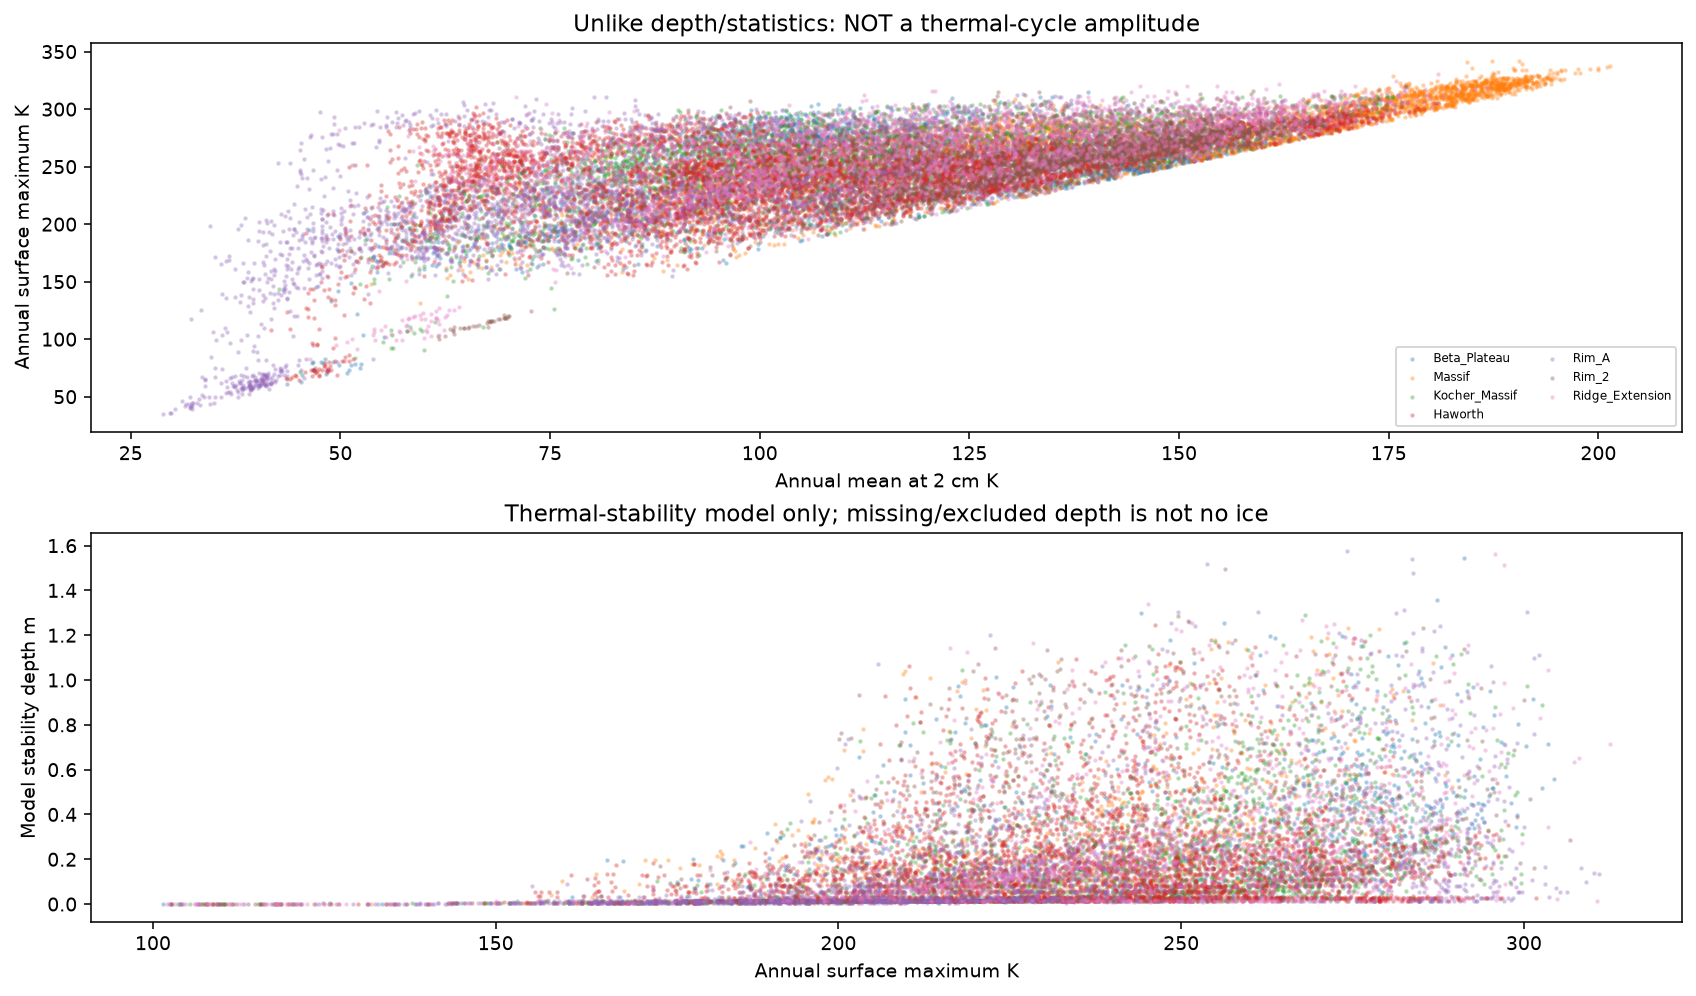

In [4]:
display(pd.read_csv(folder/'resource_depth_classes.csv'))
display(pd.read_csv(folder/'field_time_applicability.csv')[['field','unit','time_nil_reason','dated_time_series']])
display(Image(filename=str(folder/'thermal_resource_model_context.png')))

## Cross-check and proposed requirements
Original regional triangle-count/temperature semantics must still agree with Dar_044. Additional area-weighted summaries are separately named and never replace those values. No active pipeline rules or numerical limits change.

In [5]:
display(pd.read_csv(folder/'crosscheck_Dar044.csv'))
display(pd.read_csv(folder/'stage4_polar_thermal_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])

,region,old_triangles,new_triangles,absolute_mean_2cm_difference_K,absolute_surface_max_difference_K,scope
0,whole_south_product,2880000,2880000,1.421085e-14,0.0,identical original triangle-count-weighted sem...
1,A3CLR22_10_Leibnitz_Beta_Plateau,2048,2048,0.000000e+00,0.0,identical original triangle-count-weighted sem...
2,A3CLR22_11_Malapert_Massif,3486,3486,0.000000e+00,0.0,identical original triangle-count-weighted sem...
3,A3CLR22_12_deGerlache_Kocher_Massif,3121,3121,0.000000e+00,0.0,identical original triangle-count-weighted sem...
4,A3CLR22_2_Haworth,6962,6962,1.421085e-14,0.0,identical original triangle-count-weighted sem...
5,A3CLR22_3_Faustini_Rim_A,3160,3160,0.000000e+00,0.0,identical original triangle-count-weighted sem...
6,A3CLR22_4_deGerlache_Rim_2,3121,3121,0.000000e+00,0.0,identical original triangle-count-weighted sem...
7,A3CLR22_5_Connecting_Ridge_Extension,3160,3160,0.000000e+00,0.0,identical original triangle-count-weighted sem...


,id,classification,title,current_outcome,decision_logic
0,PT-G01,evidence_guard,"Keep thermal statistic, depth and model epoch ...",Unknown,Do not subtract unlike depth/statistics as a c...
1,PT-G02,evidence_guard,Native facet and footprint support before cand...,Unknown,Region bounding-box/triangle-centre context is...
2,PT-H01,conditional_hard_constraint,Applicable component thermal envelope,Unknown,Failed if qualified applicable component tempe...
3,PT-S01,conditional_soft_preference,Lower qualified thermal-control burden,Unknown,"Prefer a qualified operational burden, not uni..."
4,PT-G03,evidence_guard,Ice stability is not detection or extraction f...,Unknown,Zero model stability depth is not detected ice...


## Base conclusion
The model supplies useful spatial thermal distributions and thermal-stability context. It cannot establish a chronological mission-local equipment envelope, material response or resource capability. Local applicability and mandatory thermal outcomes remain Unknown.

In [6]:
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

{
  "subject": "polar_thermal",
  "sample": false,
  "native_triangles": 2880000,
  "tables": {
    "native_model_statistics": 32,
    "native_model_histograms": 9248,
    "regional_support": 8,
    "resource_depth_classes": 24,
    "regional_triangle_values": 25058,
    "field_time_applicability": 15,
    "crosscheck_Dar044": 8,
    "stage4_polar_thermal_proposals": 5
  },
  "time_applicability": "provider start/stop explicitly inapplicable; annual model statistics cannot supply calendar histories",
  "base_conclusion": "Spatial/model thermal tails, mesh support and ice-stability context are available. Unlike depth/statistics, unvalidated footprints and absent chronological response prevent component thermal or resource-operability conclusions.",
  "full_source_scope": "all selected native south PRP facets",
  "pipeline_changed": false,
  "adopted_limits": false,
  "operational_status": "Unknown",
  "remaining": [
    "Mission-local chronological thermal forcing and component response